In [5]:
# Salary Prediction Using Machine Learning

In [6]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
# Load Dataset
df = pd.read_csv("expected_ctc.csv")

In [8]:
#DATA EXPLORATION

In [9]:
df.head()

,IDX,Applicant_ID,Total_Experience,Total_Experience_in_field_applied,Department,Role,Industry,Organization,Designation,Education,...,Curent_Location,Preferred_location,Current_CTC,Inhand_Offer,Last_Appraisal_Rating,No_Of_Companies_worked,Number_of_Publications,Certifications,International_degree_any,Expected_CTC
0,1,22753,0,0,NaN,NaN,NaN,NaN,NaN,PG,...,Guwahati,Pune,0,N,NaN,0,0,0,0,384551
1,2,51087,23,14,HR,Consultant,Analytics,H,HR,Doctorate,...,Bangalore,Nagpur,2702664,Y,Key_Performer,2,4,0,0,3783729
2,3,38413,21,12,Top Management,Consultant,Training,J,NaN,Doctorate,...,Ahmedabad,Jaipur,2236661,Y,Key_Performer,5,3,0,0,3131325
3,4,11501,15,8,Banking,Financial Analyst,Aviation,F,HR,Doctorate,...,Kanpur,Kolkata,2100510,N,C,5,3,0,0,2608833
4,5,58941,10,5,Sales,Project Manager,Insurance,E,Medical Officer,Grad,...,Ahmedabad,Ahmedabad,1931644,N,C,2,3,0,0,2221390


In [10]:
df.shape

(25000, 29)

In [11]:
df.columns

Index(['IDX', 'Applicant_ID', 'Total_Experience',
       'Total_Experience_in_field_applied', 'Department', 'Role', 'Industry',
       'Organization', 'Designation', 'Education', 'Graduation_Specialization',
       'University_Grad', 'Passing_Year_Of_Graduation', 'PG_Specialization',
       'University_PG', 'Passing_Year_Of_PG', 'PHD_Specialization',
       'University_PHD', 'Passing_Year_Of_PHD', 'Curent_Location',
       'Preferred_location', 'Current_CTC', 'Inhand_Offer',
       'Last_Appraisal_Rating', 'No_Of_Companies_worked',
       'Number_of_Publications', 'Certifications', 'International_degree_any',
       'Expected_CTC'],
      dtype='str')

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 29 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   IDX                                25000 non-null  int64  
 1   Applicant_ID                       25000 non-null  int64  
 2   Total_Experience                   25000 non-null  int64  
 3   Total_Experience_in_field_applied  25000 non-null  int64  
 4   Department                         22222 non-null  str    
 5   Role                               24037 non-null  str    
 6   Industry                           24092 non-null  str    
 7   Organization                       24092 non-null  str    
 8   Designation                        21871 non-null  str    
 9   Education                          25000 non-null  str    
 10  Graduation_Specialization          18820 non-null  str    
 11  University_Grad                    18820 non-null  str    
 12  P

In [13]:

df.describe()

,IDX,Applicant_ID,Total_Experience,Total_Experience_in_field_applied,Passing_Year_Of_Graduation,Passing_Year_Of_PG,Passing_Year_Of_PHD,Current_CTC,No_Of_Companies_worked,Number_of_Publications,Certifications,International_degree_any,Expected_CTC
count,25000.000000,25000.000000,25000.000000,25000.000000,18820.000000,17308.000000,13119.000000,2.500000e+04,25000.000000,25000.000000,25000.000000,25000.000000,2.500000e+04
mean,12500.500000,34993.240080,12.493080,6.258200,2002.193624,2005.153571,2007.396372,1.760945e+06,3.482040,4.089040,0.773680,0.081720,2.250155e+06
std,7217.022701,14390.271591,7.471398,5.819513,8.316640,9.022963,7.493601,9.202125e+05,1.690335,2.606612,1.199449,0.273943,1.160480e+06
min,1.000000,10000.000000,0.000000,0.000000,1986.000000,1988.000000,1995.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,2.037440e+05
25%,6250.750000,22563.750000,6.000000,1.000000,1996.000000,1997.000000,2001.000000,1.027312e+06,2.000000,2.000000,0.000000,0.000000,1.306278e+06
50%,12500.500000,34974.500000,12.000000,5.000000,2002.000000,2006.000000,2007.000000,1.802568e+06,3.000000,4.000000,0.000000,0.000000,2.252136e+06
75%,18750.250000,47419.000000,19.000000,10.000000,2009.000000,2012.000000,2014.000000,2.443883e+06,5.000000,6.000000,1.000000,0.000000,3.051354e+06
max,25000.000000,60000.000000,25.000000,25.000000,2020.000000,2023.000000,2020.000000,3.999693e+06,6.000000,8.000000,5.000000,1.000000,5.599570e+06


In [14]:
# CHECK MISSING VALUES

In [15]:
df.isnull().sum()

IDX                                      0
Applicant_ID                             0
Total_Experience                         0
Total_Experience_in_field_applied        0
Department                            2778
Role                                   963
Industry                               908
Organization                           908
Designation                           3129
Education                                0
Graduation_Specialization             6180
University_Grad                       6180
Passing_Year_Of_Graduation            6180
PG_Specialization                     7692
University_PG                         7692
Passing_Year_Of_PG                    7692
PHD_Specialization                   11881
University_PHD                       11881
Passing_Year_Of_PHD                  11881
Curent_Location                          0
Preferred_location                       0
Current_CTC                              0
Inhand_Offer                             0
Last_Apprai

In [16]:
# CHECK DUPLICATE RECORDS

In [17]:
df.duplicated().sum()

np.int64(0)

In [18]:
df["Expected_CTC"].head()

0     384551
1    3783729
2    3131325
3    2608833
4    2221390
Name: Expected_CTC, dtype: int64

In [19]:
# Check how many missing values each column has
df.isnull().sum().sort_values(ascending=False)

PHD_Specialization                   11881
University_PHD                       11881
Passing_Year_Of_PHD                  11881
PG_Specialization                     7692
Passing_Year_Of_PG                    7692
University_PG                         7692
Graduation_Specialization             6180
Passing_Year_Of_Graduation            6180
University_Grad                       6180
Designation                           3129
Department                            2778
Role                                   963
Industry                               908
Last_Appraisal_Rating                  908
Organization                           908
Education                                0
Total_Experience_in_field_applied        0
IDX                                      0
Applicant_ID                             0
Total_Experience                         0
Curent_Location                          0
Preferred_location                       0
Current_CTC                              0
Inhand_Offe

In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
# DATA CLEANING

In [22]:
# Create a copy of the dataset
df_clean = df.copy()

In [23]:
# Fill missing text values
text_columns = [
    "Department",
    "Role",
    "Industry",
    "Organization",
    "Designation",
    "Graduation_Specialization",
    "University_Grad",
    "PG_Specialization",
    "University_PG",
    "PHD_Specialization",
    "University_PHD"
]

df_clean[text_columns] = df_clean[text_columns].fillna("Unknown")

In [24]:
df_clean["Last_Appraisal_Rating"].unique()

<ArrowStringArray>
[nan, 'Key_Performer', 'C', 'B', 'A', 'D']
Length: 6, dtype: str

In [25]:
number_columns = [
    "Passing_Year_Of_Graduation",
    "Passing_Year_Of_PG",
    "Passing_Year_Of_PHD"
]

In [26]:
for col in number_columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

In [27]:
df_clean["Last_Appraisal_Rating"] = df_clean["Last_Appraisal_Rating"].fillna(
    df_clean["Last_Appraisal_Rating"].mode()[0]
)

In [28]:
# Verify missing values
df_clean.isnull().sum()

IDX                                  0
Applicant_ID                         0
Total_Experience                     0
Total_Experience_in_field_applied    0
Department                           0
Role                                 0
Industry                             0
Organization                         0
Designation                          0
Education                            0
Graduation_Specialization            0
University_Grad                      0
Passing_Year_Of_Graduation           0
PG_Specialization                    0
University_PG                        0
Passing_Year_Of_PG                   0
PHD_Specialization                   0
University_PHD                       0
Passing_Year_Of_PHD                  0
Curent_Location                      0
Preferred_location                   0
Current_CTC                          0
Inhand_Offer                         0
Last_Appraisal_Rating                0
No_Of_Companies_worked               0
Number_of_Publications   

In [29]:
# EXPLORATORY DATA ANALYSIS (EDA)

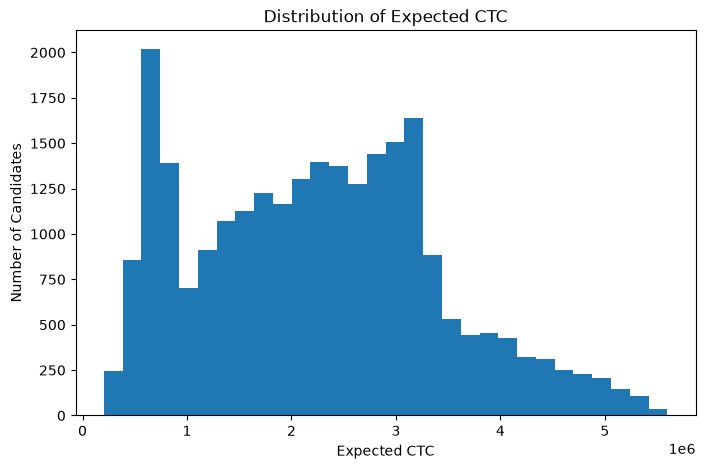

In [30]:
# Distribution of Expected Salary

plt.figure(figsize=(8,5))
plt.hist(df_clean["Expected_CTC"], bins=30)
plt.title("Distribution of Expected CTC")
plt.xlabel("Expected CTC")
plt.ylabel("Number of Candidates")
plt.show()

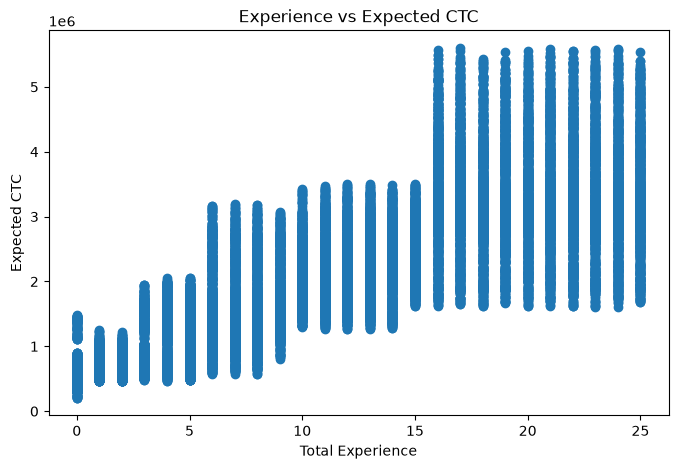

In [31]:
# Experience vs Expected Salary

plt.figure(figsize=(8,5))
plt.scatter(df_clean["Total_Experience"], df_clean["Expected_CTC"])
plt.title("Experience vs Expected CTC")
plt.xlabel("Total Experience")
plt.ylabel("Expected CTC")
plt.show()

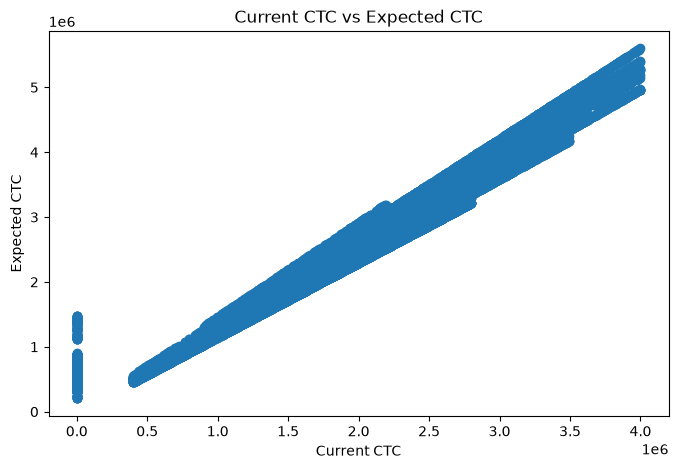

In [32]:
# Current Salary vs Expected Salary

plt.figure(figsize=(8,5))
plt.scatter(df_clean["Current_CTC"], df_clean["Expected_CTC"])
plt.title("Current CTC vs Expected CTC")
plt.xlabel("Current CTC")
plt.ylabel("Expected CTC")
plt.show()

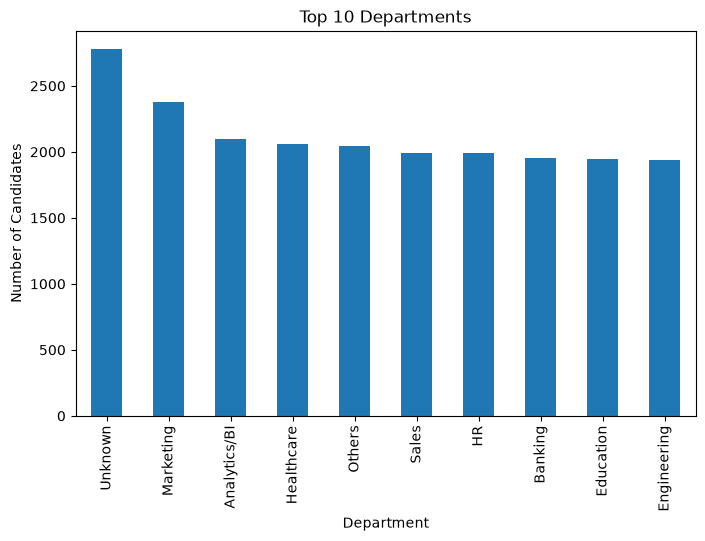

In [33]:
# Department-wise Candidate Distribution

df_clean["Department"].value_counts().head(10).plot(kind="bar", figsize=(8,5))
plt.title("Top 10 Departments")
plt.xlabel("Department")
plt.ylabel("Number of Candidates")
plt.show()

In [34]:
# FEATURE SELECTION

In [35]:
# Remove unnecessary columns

df_model = df_clean.drop(["IDX", "Applicant_ID"], axis=1)

In [36]:
df_model.head()

,Total_Experience,Total_Experience_in_field_applied,Department,Role,Industry,Organization,Designation,Education,Graduation_Specialization,University_Grad,...,Curent_Location,Preferred_location,Current_CTC,Inhand_Offer,Last_Appraisal_Rating,No_Of_Companies_worked,Number_of_Publications,Certifications,International_degree_any,Expected_CTC
0,0,0,Unknown,Unknown,Unknown,Unknown,Unknown,PG,Arts,Lucknow,...,Guwahati,Pune,0,N,B,0,0,0,0,384551
1,23,14,HR,Consultant,Analytics,H,HR,Doctorate,Chemistry,Surat,...,Bangalore,Nagpur,2702664,Y,Key_Performer,2,4,0,0,3783729
2,21,12,Top Management,Consultant,Training,J,Unknown,Doctorate,Zoology,Jaipur,...,Ahmedabad,Jaipur,2236661,Y,Key_Performer,5,3,0,0,3131325
3,15,8,Banking,Financial Analyst,Aviation,F,HR,Doctorate,Others,Bangalore,...,Kanpur,Kolkata,2100510,N,C,5,3,0,0,2608833
4,10,5,Sales,Project Manager,Insurance,E,Medical Officer,Grad,Zoology,Mumbai,...,Ahmedabad,Ahmedabad,1931644,N,C,2,3,0,0,2221390


In [37]:
df_model.shape

(25000, 27)

In [38]:
# FEATURE ENGINEERING

In [39]:
# Separate Features and Target

X = df_model.drop("Expected_CTC", axis=1)
y = df_model["Expected_CTC"]

In [40]:
X.head()

,Total_Experience,Total_Experience_in_field_applied,Department,Role,Industry,Organization,Designation,Education,Graduation_Specialization,University_Grad,...,Passing_Year_Of_PHD,Curent_Location,Preferred_location,Current_CTC,Inhand_Offer,Last_Appraisal_Rating,No_Of_Companies_worked,Number_of_Publications,Certifications,International_degree_any
0,0,0,Unknown,Unknown,Unknown,Unknown,Unknown,PG,Arts,Lucknow,...,2007.0,Guwahati,Pune,0,N,B,0,0,0,0
1,23,14,HR,Consultant,Analytics,H,HR,Doctorate,Chemistry,Surat,...,1997.0,Bangalore,Nagpur,2702664,Y,Key_Performer,2,4,0,0
2,21,12,Top Management,Consultant,Training,J,Unknown,Doctorate,Zoology,Jaipur,...,1999.0,Ahmedabad,Jaipur,2236661,Y,Key_Performer,5,3,0,0
3,15,8,Banking,Financial Analyst,Aviation,F,HR,Doctorate,Others,Bangalore,...,2005.0,Kanpur,Kolkata,2100510,N,C,5,3,0,0
4,10,5,Sales,Project Manager,Insurance,E,Medical Officer,Grad,Zoology,Mumbai,...,2010.0,Ahmedabad,Ahmedabad,1931644,N,C,2,3,0,0


In [41]:
y.head()

0     384551
1    3783729
2    3131325
3    2608833
4    2221390
Name: Expected_CTC, dtype: int64

In [42]:
# Convert categorical data into numerical format

X = pd.get_dummies(X, drop_first=True)

In [43]:
X.shape

(25000, 199)

In [44]:
# TRAIN-TEST SPLIT

In [45]:
from sklearn.model_selection import train_test_split

In [46]:
# Split dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [47]:
# Check the shape of training and testing datasets

print("X_train Shape :", X_train.shape)
print("X_test Shape  :", X_test.shape)
print("y_train Shape :", y_train.shape)
print("y_test Shape  :", y_test.shape)

X_train Shape : (20000, 199)
X_test Shape  : (5000, 199)
y_train Shape : (20000,)
y_test Shape  : (5000,)


In [48]:
# BUILD LINEAR REGRESSION MODEL

In [49]:
from sklearn.linear_model import LinearRegression

In [50]:
# Create Linear Regression model

model = LinearRegression()

In [51]:
# Train the model using training data

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](199,)","[-6946.21, 10.96,-2633.84,..., -140.56, -306.69, -423.65]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](199,)","['Total_Experience','Total_Experience_in_field_applied', 'Passing_Year_Of_Graduation',...,'Last_Appraisal_Rating_C', 'Last_Appraisal_Rating_D','Last_Appraisal_Rating_Key_Performer']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.532e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,199
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(9)


In [52]:
# Predict salary on testing data

y_pred = model.predict(X_test)

In [53]:
# Display first 10 predicted salaries

print(y_pred[:10])

[2984276.20931234 1342079.203768   3321594.74605804 2962267.02237681
 1205931.2808166  2405196.60754852 1501830.75447471 2104547.53949508
 3517001.51127402  736542.73373195]


In [54]:
# MODEL EVALUATION

In [55]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [56]:
# Calculate evaluation metrics

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = mse ** 0.5

r2 = r2_score(y_test, y_pred)

In [57]:
# Display evaluation results

print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R2 Score:", r2)

Mean Absolute Error (MAE): 131856.84188585542
Mean Squared Error (MSE): 30990712793.126118
Root Mean Squared Error (RMSE): 176041.7927457174
R2 Score: 0.9770859473698165


In [58]:
# Compare Actual and Predicted Values

In [59]:
# Create comparison table

comparison = pd.DataFrame({
    "Actual Salary": y_test.values,
    "Predicted Salary": y_pred
})

comparison.head(10)

,Actual Salary,Predicted Salary
0,3113073,2.984276e+06
1,1263089,1.342079e+06
2,3638037,3.321595e+06
3,2759980,2.962267e+06
4,1040303,1.205931e+06
5,2208350,2.405197e+06
6,1281873,1.501831e+06
7,2322435,2.104548e+06
8,3219206,3.517002e+06
9,650182,7.365427e+05


In [60]:
 # Actual vs Predicted Salary Visualization

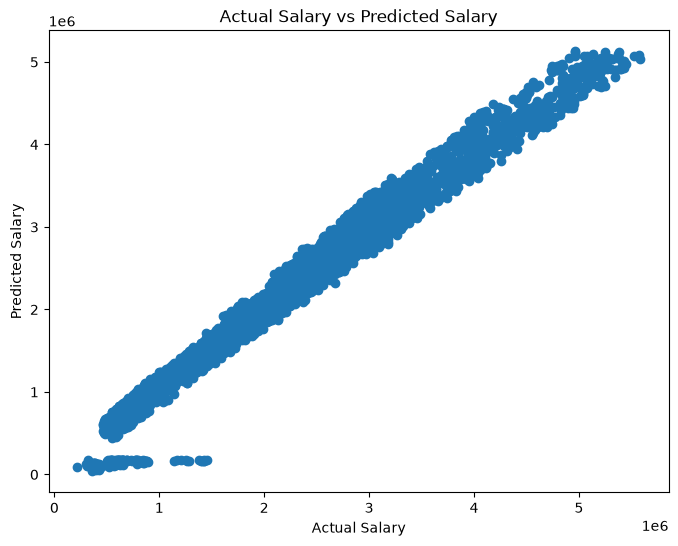

In [61]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual Salary vs Predicted Salary")

plt.show()

In [62]:
# BUILD DECISION TREE REGRESSOR

In [63]:
from sklearn.tree import DecisionTreeRegressor

In [64]:
# Create Decision Tree model

dt_model = DecisionTreeRegressor(random_state=42)

In [65]:
# Train Decision Tree model

dt_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes 

In [66]:
# Predict using Decision Tree

dt_pred = dt_model.predict(X_test)

In [98]:
# Display first 10 predictions

print(dt_pred[:10])

[3111486. 1282101. 3625571. 2759714. 1039120. 2212695. 1283175. 2308163.
 3196198.  621514.]


In [68]:
# Evaluate Decision Tree model

dt_mae = mean_absolute_error(y_test, dt_pred)

dt_mse = mean_squared_error(y_test, dt_pred)

dt_rmse = dt_mse ** 0.5

dt_r2 = r2_score(y_test, dt_pred)

print("Decision Tree MAE :", dt_mae)
print("Decision Tree MSE :", dt_mse)
print("Decision Tree RMSE :", dt_rmse)
print("Decision Tree R2 Score :", dt_r2)

Decision Tree MAE : 12259.3746
Decision Tree MSE : 665176712.8114
Decision Tree RMSE : 25791.02000331511
Decision Tree R2 Score : 0.999508178649924


In [69]:
# BUILD RANDOM FOREST REGRESSOR

In [70]:
from sklearn.ensemble import RandomForestRegressor

In [71]:
# Create Random Forest model

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

In [72]:
# Train Random Forest model

rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [73]:
# Predict using Random Forest

rf_pred = rf_model.predict(X_test)

In [74]:
# Display first 10 predictions

print(rf_pred[:10])

[3111860.96 1253528.84 3620495.08 2770302.58 1065772.47 2194498.26
 1288510.85 2321452.98 3266414.51  627917.88]


In [76]:
# Evaluate Random Forest model

rf_mae = mean_absolute_error(y_test, rf_pred)

rf_mse = mean_squared_error(y_test, rf_pred)

rf_rmse = rf_mse ** 0.5

rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest MAE :", rf_mae)
print("Random Forest MSE :", rf_mse)
print("Random Forest RMSE :", rf_rmse)
print("Random Forest R2 Score :", rf_r2)

Random Forest MAE : 11336.890816000001
Random Forest MSE : 510472046.0909369
Random Forest RMSE : 22593.628440136323
Random Forest R2 Score : 0.9996225648823102


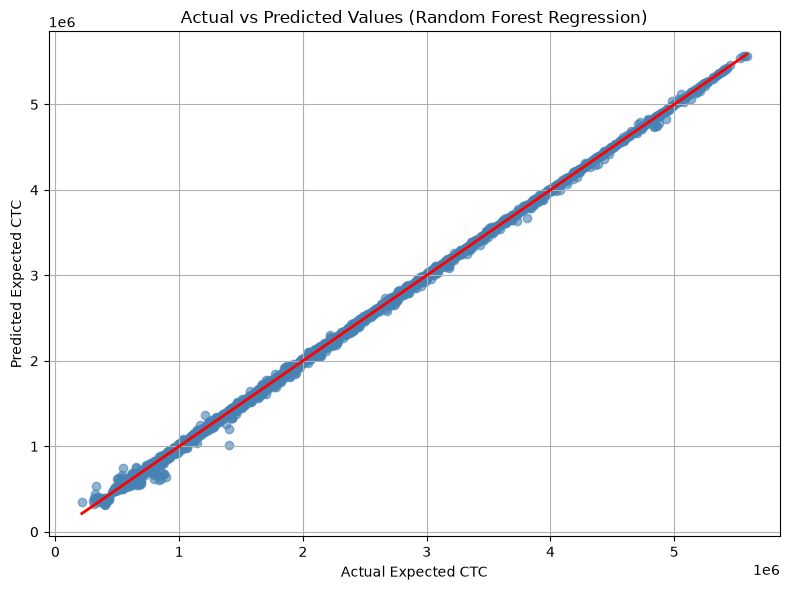

In [99]:

# Actual vs Predicted Values (Random Forest)

plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    rf_pred,
    color="steelblue",
    alpha=0.6
)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linewidth=2
)

plt.xlabel("Actual Expected CTC")
plt.ylabel("Predicted Expected CTC")
plt.title("Actual vs Predicted Values (Random Forest Regression)")

plt.grid(True)

plt.tight_layout()

plt.show()

In [77]:
# Model Comparison

In [78]:
# Compare all models

comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        mae,
        dt_mae,
        rf_mae
    ],
    "RMSE": [
        rmse,
        dt_rmse,
        rf_rmse
    ],
    "R2 Score": [
        r2,
        dt_r2,
        rf_r2
    ]
})

comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,131856.841886,176041.792746,0.977086
1,Decision Tree,12259.374600,25791.020003,0.999508
2,Random Forest,11336.890816,22593.628440,0.999623


In [79]:
# FEATURE IMPORTANCE

In [80]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
5,Current_CTC,0.985274
196,Last_Appraisal_Rating_C,0.004046
197,Last_Appraisal_Rating_D,0.004003
92,Education_PG,0.001512
91,Education_Grad,0.001274
194,Inhand_Offer_Y,0.000737
4,Passing_Year_Of_PHD,0.000514
0,Total_Experience,0.000476
117,University_Grad_Unknown,0.000298
103,Graduation_Specialization_Unknown,0.000288


In [ ]:
#Top 10 Important Features

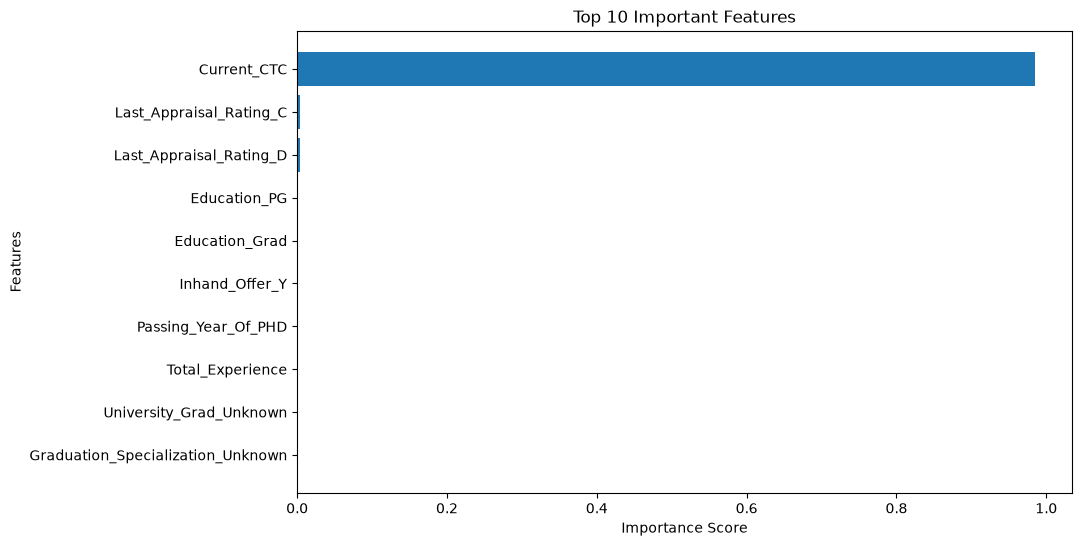

In [81]:
plt.figure(figsize=(10,6))

plt.barh(
    feature_importance["Feature"].head(10),
    feature_importance["Importance"].head(10)
)

plt.title("Top 10 Important Features")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.gca().invert_yaxis()

plt.show()

In [83]:
# STEP 19 : BUILD DEPLOYMENT PIPELINE

In [ ]:
#step1

In [84]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

In [ ]:
#step2 

In [85]:
df_pipeline = df_clean.copy()

In [ ]:
#step3

In [86]:
X = df_pipeline.drop(
    ["IDX", "Applicant_ID", "Expected_CTC"],
    axis=1
)

y = df_pipeline["Expected_CTC"]

In [ ]:
#step4

In [87]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object", "string"]
).columns

In [ ]:
#step5

In [88]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [ ]:
#step6

In [89]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [ ]:
#step7

In [90]:
from sklearn.ensemble import RandomForestRegressor

pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=100,
                random_state=42
            )
        )
    ]
)

In [ ]:
#step8

In [91]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [ ]:
#step9

In [92]:
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](26,)","['Total_Experience','Total_Experience_in_field_applied','Department',..., 'Number_of_Publications','Certifications','International_degree_any']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,26
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data pas

In [ ]:
#step10

In [ ]:
pred = pipeline.predict(X_test)

from sklearn.metrics import r2_score

print("R2 Score:", r2_score(y_test, pred))

R2 Score: 0.9996756602047389


In [ ]:
# SAVE BEST MODEL

In [ ]:
joblib.dump(
    pipeline,
    "salary_prediction_pipeline.pkl"
)

In [ ]:
X.columns

Index(['Total_Experience', 'Total_Experience_in_field_applied', 'Department',
       'Role', 'Industry', 'Organization', 'Designation', 'Education',
       'Graduation_Specialization', 'University_Grad',
       'Passing_Year_Of_Graduation', 'PG_Specialization', 'University_PG',
       'Passing_Year_Of_PG', 'PHD_Specialization', 'University_PHD',
       'Passing_Year_Of_PHD', 'Curent_Location', 'Preferred_location',
       'Current_CTC', 'Inhand_Offer', 'Last_Appraisal_Rating',
       'No_Of_Companies_worked', 'Number_of_Publications', 'Certifications',
       'International_degree_any'],
      dtype='str')

In [ ]:
print(list(X.columns))

['Total_Experience', 'Total_Experience_in_field_applied', 'Department', 'Role', 'Industry', 'Organization', 'Designation', 'Education', 'Graduation_Specialization', 'University_Grad', 'Passing_Year_Of_Graduation', 'PG_Specialization', 'University_PG', 'Passing_Year_Of_PG', 'PHD_Specialization', 'University_PHD', 'Passing_Year_Of_PHD', 'Curent_Location', 'Preferred_location', 'Current_CTC', 'Inhand_Offer', 'Last_Appraisal_Rating', 'No_Of_Companies_worked', 'Number_of_Publications', 'Certifications', 'International_degree_any']


In [ ]:
categorical_columns = [
    "Department",
    "Role",
    "Industry",
    "Organization",
    "Designation",
    "Education",
    "Graduation_Specialization",
    "University_Grad",
    "PG_Specialization",
    "University_PG",
    "PHD_Specialization",
    "University_PHD",
    "Curent_Location",
    "Preferred_location",
    "Last_Appraisal_Rating",
    "International_degree_any"
]

for col in categorical_columns:
    print(f"\n{col}")
    print(df_clean[col].unique())


Department
<ArrowStringArray>
[       'Unknown',             'HR', 'Top Management',        'Banking',
          'Sales',    'Engineering',         'Others',   'Analytics/BI',
      'Education',      'Marketing',     'Healthcare',    'IT-Software',
       'Accounts']
Length: 13, dtype: str

Role
<ArrowStringArray>
[             'Unknown',           'Consultant',    'Financial Analyst',
      'Project Manager',   'Area Sales Manager',            'Team Lead',
              'Analyst',               'Others',                  'CEO',
     'Business Analyst',        'Sales Manager',     'Bio statistician',
            'Scientist',   'Research Scientist',                 'Head',
            'Associate',    'Senior Researcher',      'Sales Execituve',
 'Sr. Business Analyst',    'Principal Analyst',       'Data scientist',
           'Researcher',       'Senior Analyst',            'Professor',
        'Lab Executuve']
Length: 25, dtype: str

Industry
<ArrowStringArray>
[   'Unknown',  'Analy